## 시계열 데이터란?
### 시계열 데이터의 정의
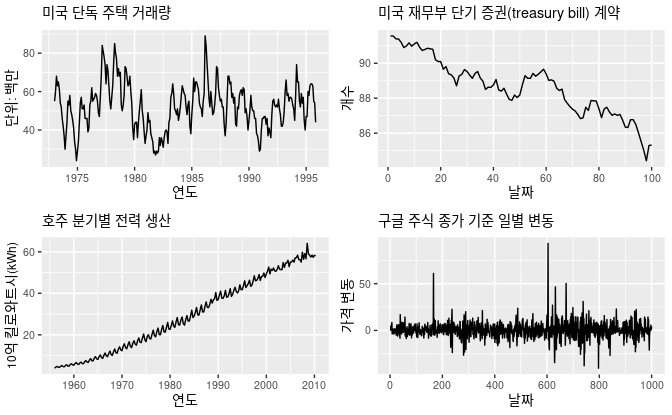 <br>
시간의 흐름에 따라 일정한 간격, 순서대로 관측 및 기록된 데이터 ex. 주가, 기온 <br>
- $t$  : 시점 (time index) — 1일, 2일, 3일… 혹은 1월, 2월, 3월…
- $Y_t$ : $t$ 시점에 관측된 값
- $T$ : 마지막 관측 시점

#### 시계열 데이터 조건
1. 시간 순서가 의미를 가진다.
2. 관측 간격이 일정하다.

### 시계열 데이터의 특성
1. 시간 의존성
데이터가 시간에 따라 변하고, 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질
    - 과거의 값이 현재의 값에 영향을 미친다.
    - 보통 가까운 과거일수록 영향이 크다.
    - 순서를 섞으면 안 된다.
2. 계절성 & 추세
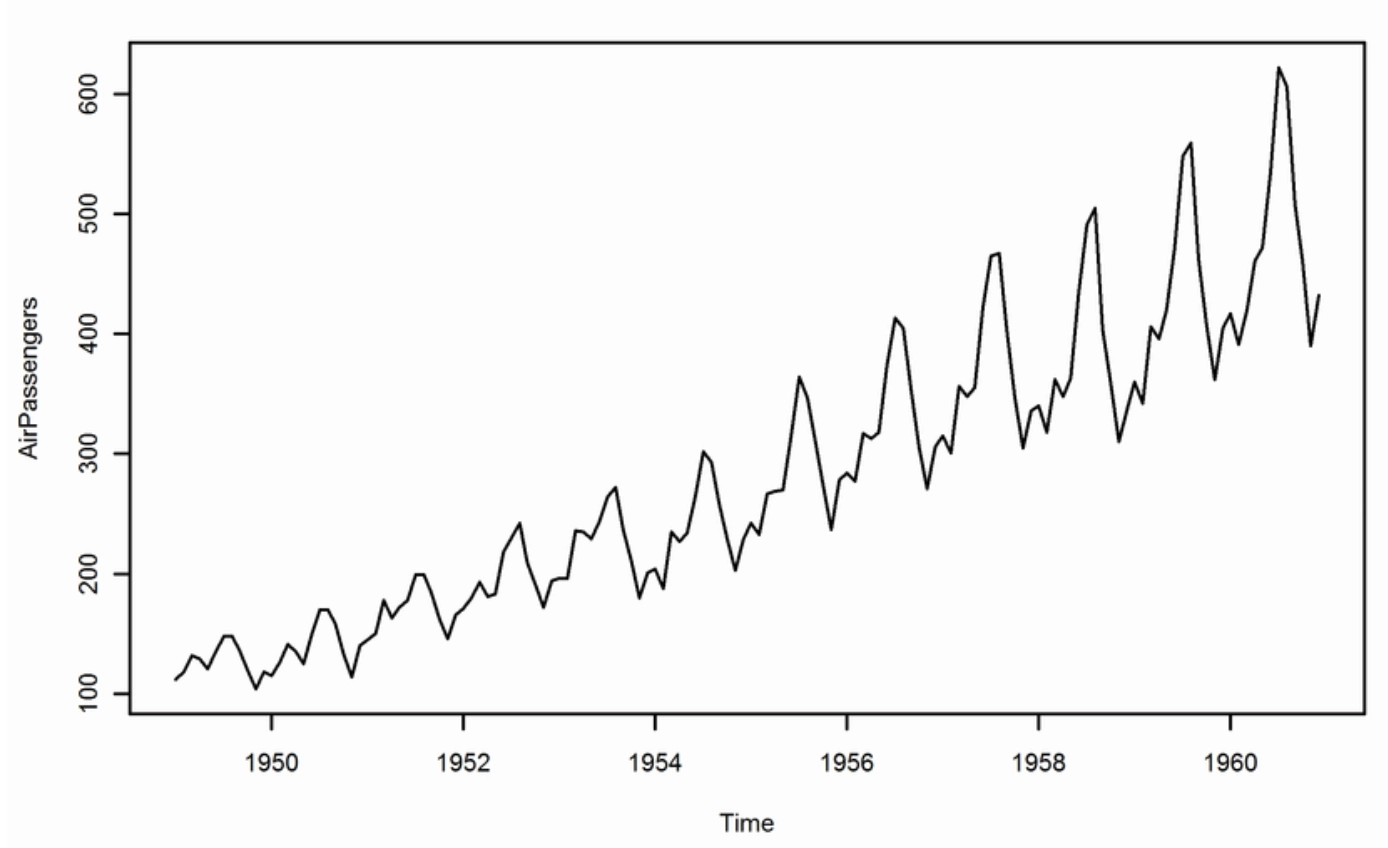 <br>
계절성: 일정한 주기(일, 주, 월, 년 등)로 비슷한 패턴이 반복되는 성질 <br>
추세: 시간의 흐름에 따라 데이터가 장기적으로 증가하거나 감소하는 방향성

3. 자기상관성
**시계열의 가장 중요한 특성** <br>
자기 자신끼리 상관관계를 갖는 특성 <br>
한 시계열 안에서 현재 값과 과거 값이 얼마나 비슷하게 움직이는지를 나타내는 정도 <br>
    - 1에 가까움: 과거에도 높았으면 지금도 높다 (비례)
    - -1에 가까움: 과거에 높았으면 지금은 낮다 (반비례)
    - 0에 가까움: 과거와 지금이 관계없다.

- 자기상관성의 문제점
    1. 오차항 독립성 가정 위반
    2. 허위 상관관계
    3. 예측의 어려움 & 모델 복잡성 증가

### 시계열 데이터의 분석요인
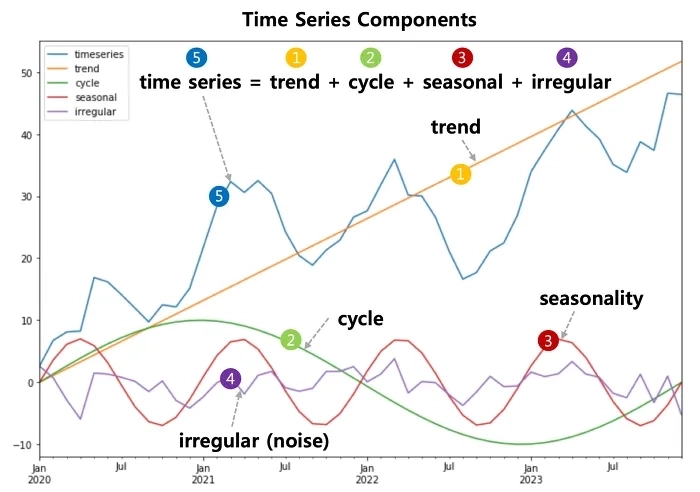 <br>
1. 추세 요인
시계열이 시간 전반에 걸쳐 증가하거나 감소하는 경향성을 나타내는 요인

2. 계절 요인
1년 이내의 일정한 주기로 같은 패턴이 반복되는 요인

3. 순환 요인
계절성보다 더 길고 불규칙한 주기로 반복되는 변동

4. 불규칙 요인
시계열에서 추세, 계절, 순환요인을 모두 제거하고 남은 나머지 움직임

## 시계열 데이터 전처리
### 전처리 프로세스
1. 데이터 확인
2. 결측치 탐지 및 처리
3. 이상치 탐지 및 처리
4. 평활화
5. 요소분해
6. 정상성 판단 및 후보

### 결측치/이상치 처리
#### 결측치 처리 방법
| 방법 | 설명 | 시계열에서의 한계 |
| --- | --- | --- |
| **삭제** | 결측치가 있는 시점을 제거 | 관측 간격이 깨짐 → 결측이 매우 적고, 데이터 맨 앞이나 맨 뒤일 때만 고려 |
| **단순 대치** | 평균, 중앙값, 최빈값으로 채움 | 추세와 계절성을 무시함 |
| **보간** | 앞뒤 관측값을 이용해 사이의 값을 추정 | 앞뒤 값이 있어야 함 → **시계열에서 가장 많이 사용** |
| **이동평균 대치** | 결측 시점 주변 일정 구간의 평균으로 채움 | 구간 크기를 정해야 함|
| **머신러닝 기법** | KNN, 회귀 모델 등으로 결측값을 예측해서 채움 | 정교하지만 복잡하고 계산량이 많음 |
---------------------------------------------------------------
시계열에서 가장 많이 사용하는 방법은 보간법. <br>
보간법이란, 주어진 데이터 포인트 값을 이용해 두 관측값 사이의 비어있는 값을 추정하는 방법 <br>
---------------------------------------------------------------
| 데이터 상황 | 추천 보간법 |
| --- | --- |
| 변화가 완만하고 일정한 데이터 | 선형 보간 |
| 곡선 형태로 부드럽게 변하는 데이터 | 스플라인 보간 |
| 값이 계단처럼 유지되는 데이터 (ex. 가격표, 설정값) | 조각별 상수 보간 (ffill) |
| 잘 모르겠을 때 | **선형 보간부터** 시작 |

##### 보간법 과정
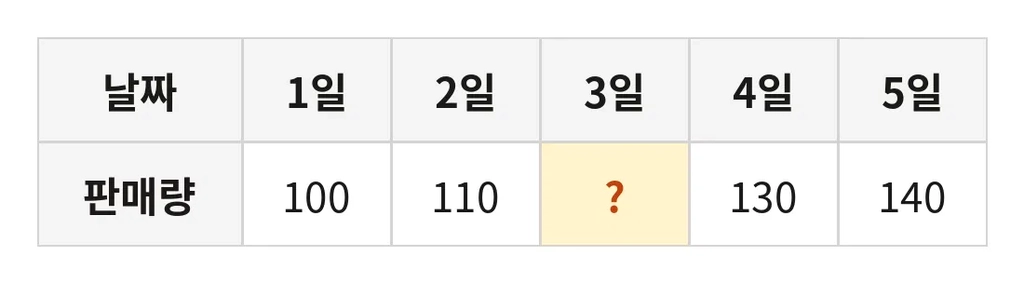 <br>
1. 결측 위치 확인: 3일 값이 비어 있음
2. 앞뒤 관측값 확인: 2일은 110, 4일은 130
3. 두 점을 연결하는 규칙 정하기: 직선으로 이을지, 곡선으로 이을지 → 이 선택이 보간 방법의 종류
4. 값 추정: 직선으로 이으면 3일 값은 두 값의 중간인 120

#### 이상치 탐지 방법
1. IQR
데이터를 크기순으로 나열했을 때 하위 25% 지점(Q1)과 상위 25% 지점(Q3) 사이의 범위
> 적용 방법: 주기성이 없거나 비교적 안정적인 구간의 값들에서 이상치 탐지할 때 사용, 일정 구간을 이동하면서 구간마다 IQR을 계산하거나 추세나 계절성을 제거한 잔차에 적용

2. Z-score
각 값이 평균에서 몇 표준편차만큼 떨어져 있는지를 계산하는 방법
$$ Z = \frac{x - \mu}{\sigma} $$

>적용 방법: 계절성/추세가 약하거나 값의 변동폭이 일정한 시계열에서 효과적, 이동 평균과 이동 표준편차로 구간마다 Z-score를 계산하면 추세의 영향을 줄일 수 있음 (Rolling Z-score)

3. STL 분해
시계열을 추세(T), 계절(S), 잔차(R)로 분해하는 방법 <br>
$$ Y_t = T_t + S_t + R_t $$

>적용 방법: 잔차가 특정 임곗값을 초과하면 이상치 탐지, 계절성이나 추세가 뚜렷한 시계열(예: 일별 매출, 센서 데이터)에 적합, 잔차에 IQR이나 Z-score 등 통계적 기준을 추가 적용해 이상 탐지 가능

#### 이상치 탐지 모델
1. 분류 및 회귀 트리(CART)
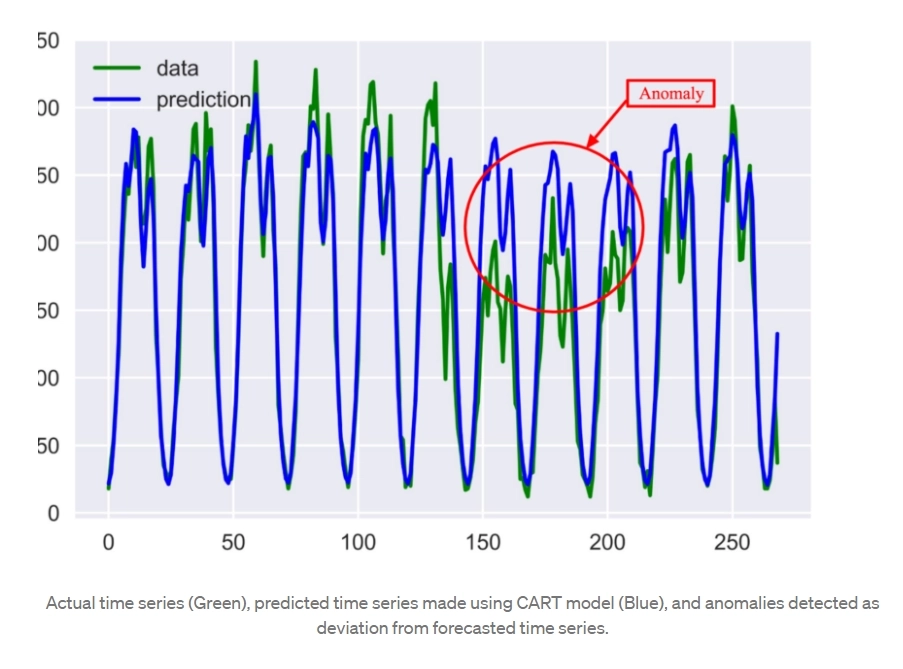 <br>
- **CART(Classification And Regression Tree)**는 데이터를 조건에 따라 계속 나눠 가며 예측하는 의사결정나무 모델
- 이상치 탐지에서는 예측 오차가 일정 임계값 이상인 지점을 이상치로 판단
>적용 방법: 과거 구간의 값을 입력으로 하여 다음 시점의 값을 예측하고, 예측오차 기반으로 이상치를 판단

2. 클러스터링 기반 이상 탐지
- **원리**
비슷한 데이터끼리 묶는 **군집화(Clustering)**를 한 뒤, **어느 군집에도 잘 속하지 않는 데이터**를 이상치로 판단
    
    - **K-means** : 군집 중심에서 너무 멀리 떨어진 데이터를 이상치로 판단
    - **DBSCAN** : 밀집된 영역에 속하지 못하고 혼자 떨어진 데이터를 노이즈(이상치)로 분류

>적용 방법: 시계열의 특징을 추출한 후, 각 시점을 벡터로 표현해 클러스터링 수행 ( ex. 최근 5분 평균, 표준편차 기울기 등의 특징), 중심으로부터의 거리나 군집 밀도를 기준으로 이상치 판단

3. 오토 인코더
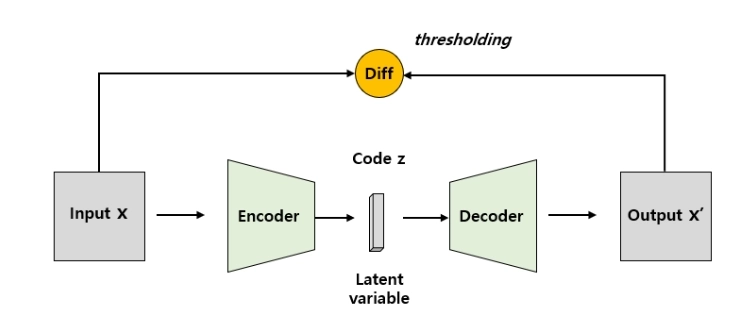 <br>
입력 데이터를 **작게 압축(Encoder)**했다가 다시 **원래대로 복원(Decoder)**하도록 학습하는 신경망, 정상 데이터만으로 학습시키면, 모델은 정상 패턴만 잘 복원 <br>
-> 이상치가 들어오면 제대로 복원하지 못하고, **원본과 복원값의 차이(복원 오차)**가 커짐. 이 오차가 기준보다 크면 이상치로 판단

>적용 방법: LSTM Autoencoder를 사용하면 시계열의 시간적 의존성까지 학습 가능. 시계열을 일정 길이로 잘라 정상 구간을 학습시키고, 테스트 구간의 복원오차가 큰 곳을 이상으로 탐지

#### 이상치 처리 방법
- **삭제**
    - 이상치를 제거하는 방법
    - 단, 시계열에서 그냥 지우면 관측 간격이 깨지므로 **값을 비워서(NaN) 결측치로 바꾼 뒤** 다시 채워주는 경우가 다수
- **단순 대치**
    - 평균, 중앙값 등으로 바꾸는 방법
    - 간단하지만 추세와 계절성을 무시한다는 한계
- **보간**
    - 이상치를 결측치로 바꾼 뒤, 앞뒤 값으로 **보간해서 채우는 방법**
    - 시간 흐름을 반영할 수 있어 시계열에서 많이 사용

### 평활화
시계열 데이터의 자잘한 오르내림(노이즈)을 줄여 데이터를 부드럽게 만드는 기술

#### 이동평균
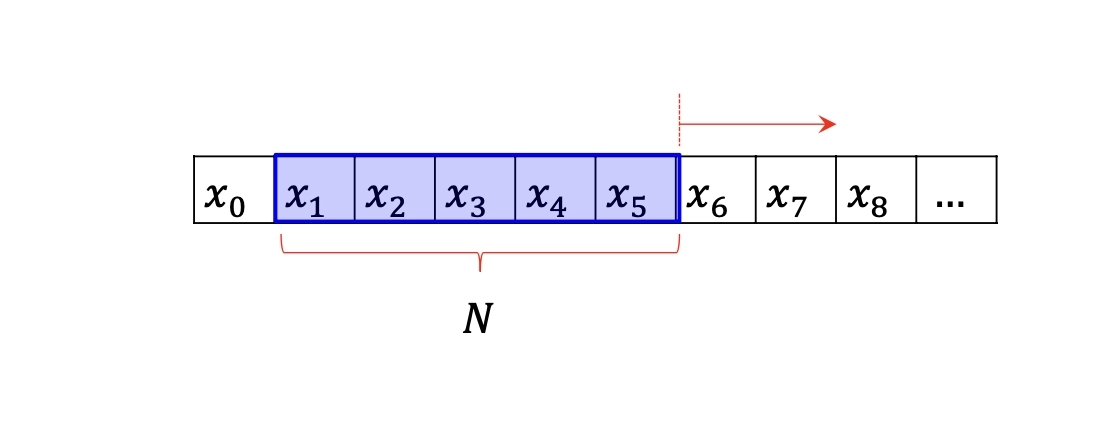 <br>
$$
    MA_t = \frac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N}
$$
가장 대표적인 평활화 방법 <br>
일정한 개수의 연속된 데이터를 묶어 평균을 내고, 그 묶음을 한 칸씩 옮겨가며 평균을 계속 계산하는 방법 <br>
t 시점의 이동평균: t 시점부터 N개 전까지의 값을 모두 더해 N으로 나눈 값 <br>
N이 클수록 더 긴 기간의 데이터를 평균에 포함시킴 -> 그래프가 매끄러워짐 <br>
무조건 N이 크다고 좋은 것 x 보고자 하는 흐름의 길이에 맞게 정해야 함.

##### 이동평균 사용 목적
1. **노이즈 제거 & 추세 파악**
2. **계절성 제거**
3. **결측치·이상치 대치**
4. **예측의 기초 자료**

##### 이동평균 유형
1. 단순 이동평균
2. 가중 이동평균
3. 지수 이동평균

### 요소분해
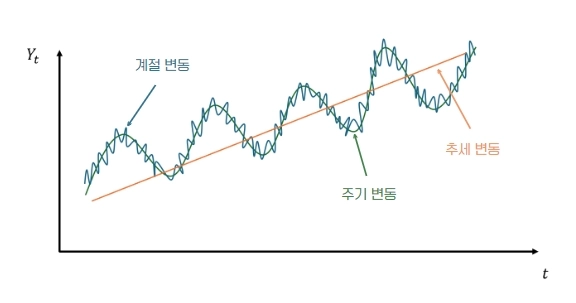 <br>
섞여 있는 시계열을 각각의 요인으로 다시 나누는 과정 <br>
- **Tₜ** : 추세 요인 (Trend)
- **Sₜ** : 계절 요인 (Seasonal)
- **Cₜ** : 순환 요인 (Cycle)
- **Rₜ** : 불규칙 요인 (Residual, 잔차)

→ 실제 관측값 Yₜ는 이 네 요인이 어떤 방식(f)으로 결합된 결과

#### 가법모형 / 승법모형
##### 가법모형
$$
    Y_t = T_t + S_t + R_t
$$ 
- 시계열 = 추세, 계절, 잔차를 **더한 값**
- 시계열의 관측 값은 변동 요인들의 **가법(+)**으로 설명될 수 있다고 가정
- **각 변동 요인들이 독립적으로 더해지며, 모든 요소의 영향이 일정**
- 시계열 전체에서 계절성의 진폭이 일정할 때 적합

##### 승법모형
$$
    Y_t = T_t \times S_t \times R_t
$$
- 시계열 = 추세, 계절, 잔차를 **곱한 값입니다.**
- 시계열의 관측 값은 변동 요인들의 **승법(x)**으로 설명될 수 있다고 가정
- **추세가 커질수록 계절성이나 불규칙성의 효과도 비례해서 커짐**
- 진폭이 시간에 따라 달라질 때 적합

#### Seasonal Decompose / STL
##### Seasonal Decompose
- **원리**
    - 가장 기본적이고 전통적인 분해 방법으로, **이동평균(MA)으로 추세를 먼저 뽑아낸 뒤** 나머지에서 계절과 잔차를 차례로 분리

- **작동방식**
    1. **추세 추출**
        - 중심 이동 평균을 적용하여 추세 성분(T)을 추정
    2. **Detrending (추세 제거)**
        - 원래 데이터에서 추세(T)를 제거
        - 가법 모형 : Y − T / 승법 모형 : Y ÷ T
        - 이제 데이터에는 **계절 + 잔차**만 남아있음. 
    3. **계절성 추정**
        - 추세를 제거한 데이터에서 동일한 계절 인덱스에 해당하는 값들의 평균을 취해 계절 요인(S)을 도출 이때 연간 평균이 0이 되도록 정규화
    4. **잔차 산출**
        - 원래 데이터에서 추세와 계절을 모두 제거하고 남은 값이 **잔차(R)**
        - 가법 모형 : Y − T − S / 승법 모형 : Y ÷ (T × S)

##### STL
- **원리**
    - 데이터 전체에 선 하나를 긋는 대신, **각 지점마다 주변 데이터만 사용해서** 작은 회귀선을 그리고 이를 이어 붙여 부드러운 곡선을 만드는 방법. 가까운 데이터일수록 더 큰 가중치를 줌.
        
        → 전체를 하나의 규칙으로 맞추지 않고 **구간마다 유연하게** 맞추기 때문에, 시간에 따라 바뀌는 추세와 계절 패턴도 잘 잡아냄.
- **작동방식**
    
    STL은 Inner Loop와 Outer Loop의 이중 반복 구조로 구성
    
    - **Inner Loop: 추세와 계절을 번갈아 추정**
        1. 원래 데이터에서 현재 추세를 빼서 **추세를 제거**
        2. 추세를 제거한 데이터를 **같은 계절 위치끼리** 모아 LOESS로 부드럽게 만듦 → **계절 요인(S)** 추정
        3. 원래 데이터에서 계절 요인을 빼서 **계절성을 제거**
        4. 계절성을 제거한 데이터에 LOESS를 적용 → **추세 요인(T)** 추정
        5. 새로 구한 추세로 다시 1번부터 반복하며 T와 S를 점점 정확하게 다듬음
    - **Outer Loop: 이상치 영향 줄이기**
        1. Inner Loop가 끝나면 **잔차(R = Y − T − S)**를 계산
        2. 잔차가 유독 큰 시점(이상치일 가능성이 높은 시점)에 **작은 가중치**를 부여
        3. 이 가중치를 반영해서 **Inner Loop를 다시 수행**
        
        → 이상치가 추세와 계절 추정을 왜곡하지 못하게 막아줘요. 이를 **강건(robust)한 분해**라고 함.

## 정상성 판단
### 정상성의 정의 / 강한 정상성과 약한 정상성
정상성(Stationarity)이란 시계열의 통계적 특성이 시간에 따라 변하지 않는 성질 <br>
정상성의 핵심 = ‘시간에 상관없이’ 일정한 성질을 띄고 있다
- 강한 정상성
시계열의 확률분포 자체가 시간에 따라 전혀 변하지 않는 성질 <br>
평균, 분산뿐 아니라 왜도, 첨도 등 분포의 모든 특성이 시간에 따라 변하지 않고 일정

- 약한 정상성 
분포 전체가 아니라 평균, 분산, 자기공분산만 시간에 따라 변하지 않으면 되는 성질 <br>
강한 정상성보다 조건이 느슨해서 현실 데이터에도 적용 가능

1. **평균이 일정하다** : 모든 시점의 평균이 같은 값 μ
2. **분산이 일정하다** : 모든 시점의 분산이 같은 값 σ² (무한대가 아님)
3. **자기공분산이 시차에만 의존한다** : 두 시점 사이의 공분산은 **특정 시점(t)이 아니라 시간의 간격(h)**에만 달려 있음

### 정상성의 판단 - 시각 / 통계
#### 시각적으로 정상성 파악하기
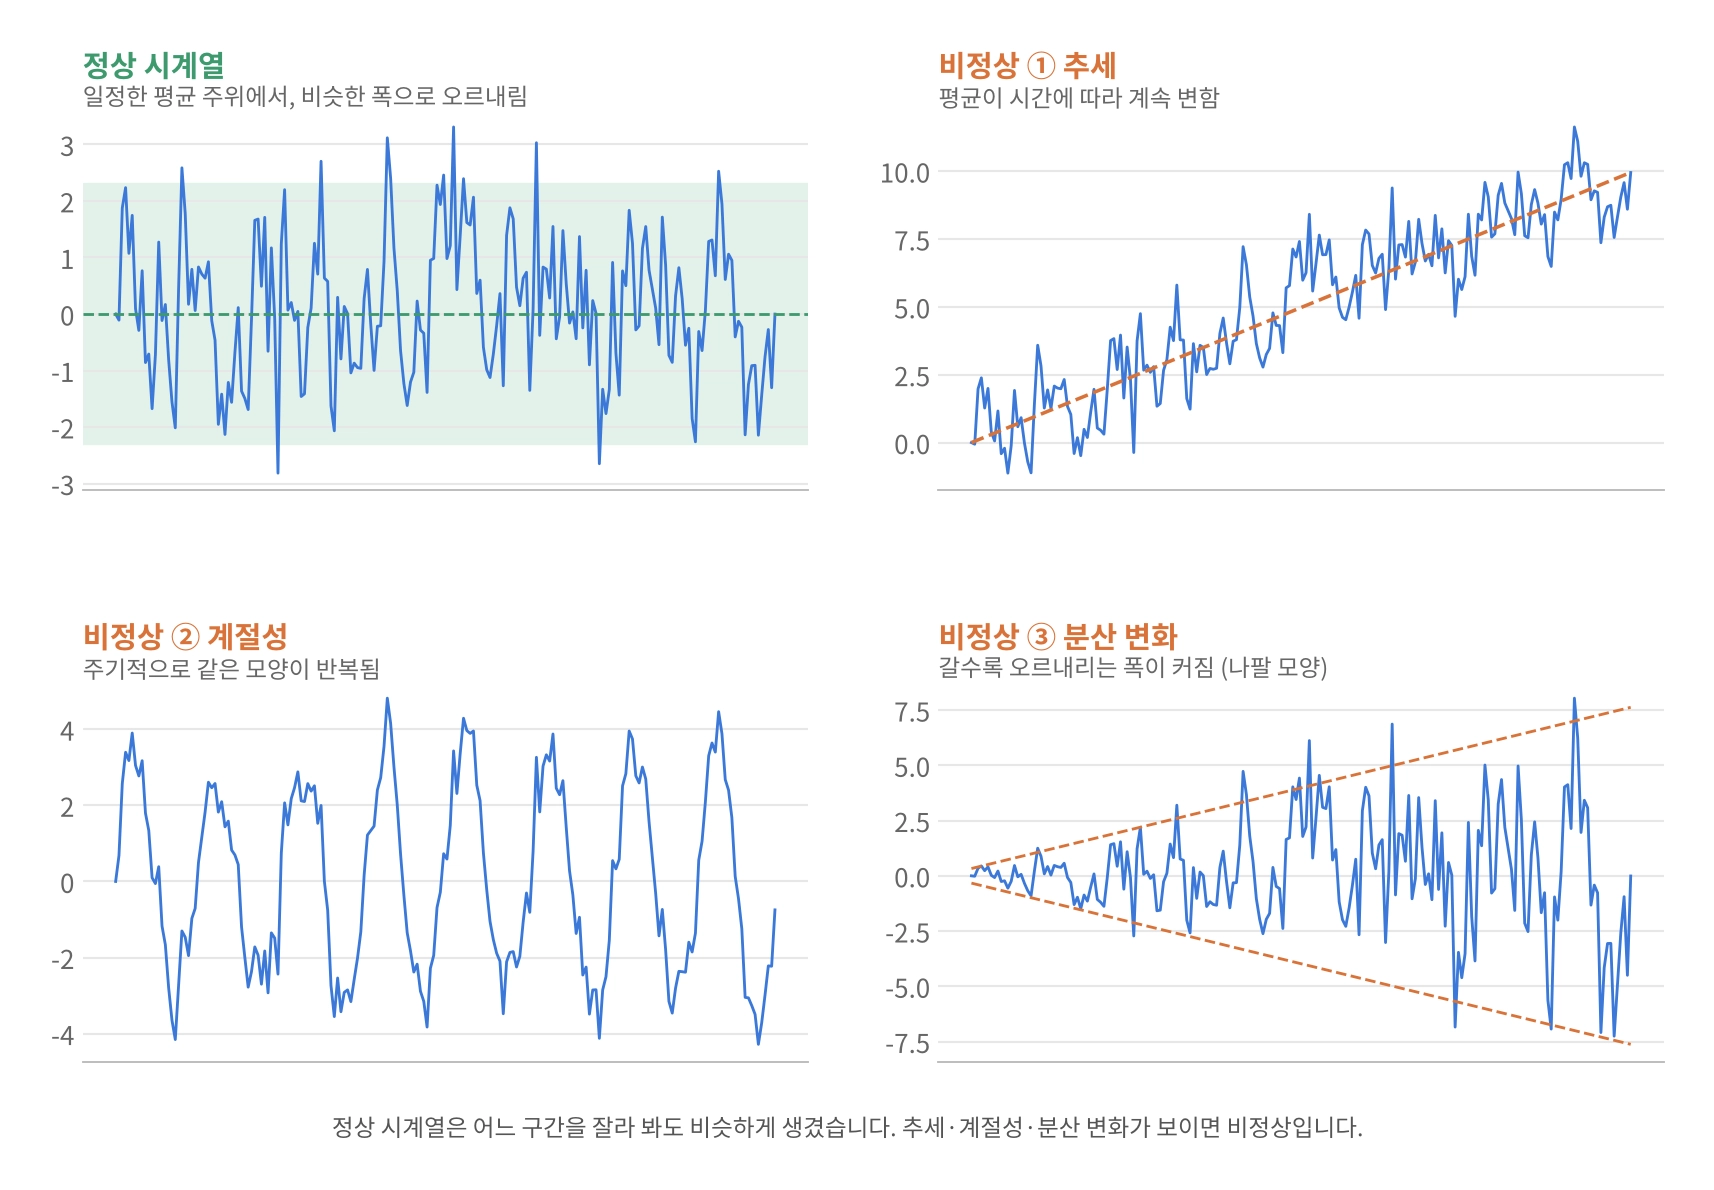 <br>
- 정상 시계열의 대표적인 그래프 특징
    - 일정한 수평선(평균)을 중심으로 위아래로 오르내림
    - 오르내리는 폭이 시간에 상관없이 비슷함
    - 평균에서 벗어나도 다시 평균으로 돌아오는 경향 (평균 회귀)
    - 특정 주기로 반복되는 패턴이 없음

- 비정상 시계열의 대표적인 그래프 특징
    - **추세** : 그래프가 계속 오르거나 내림 → 평균이 변함
    - **계절성** : 일정한 주기로 같은 모양이 반복됨 → 시점에 따라 평균이 달라짐
    - **분산 변화** : 시간이 지날수록 오르내리는 폭이 커지거나 작아짐 (나팔 모양) → 분산이 변함

#### 통계적 검정
단위근: 시계열을 표현하는 식의 근(해)이 1이 되는 경우 <br>
시계열에 단위근이 있으면 과거의 충격이 사라지지 않고 계속 쌓여서, 데이터가 평균으로 돌아오지 않고 무작위로 떠돌게 됨. <br>
정상시계열인지 비정상 시계열인지 구분하기 위해 단위근 여부를 확인하는 과정이 필요

##### 단위근 검정 방법
"단위근이 있는지"를 가설검정으로 판단

1. ADF
시계열에 ”단위근이 있는지”를 검정하는 가장 대표적인 방법으로, “이 시계열이 비정상이 아님을 증명하자”는 관점에서 출발 <br>
ADF는 시계열이 과거 값에 얼마나 의존하는지를 측정
- 가정
    - **귀무가설(H₀)** : 단위근이 **있다** → **비정상** 시계열
    - **대립가설(H₁)** : 단위근이 **없다** → **정상** 시계열

 ⇒ **p-value < 0.05**이면 귀무가설을 기각 → **정상**

2. KPSS
“이 시계열이 정상임을 반증하자”는 관점에서 출발 <br>
시계열이 일정한 평균 수준을 유지하는지를 측정 <br>
- 가정
    - **귀무가설(H₀)** : 시계열이 **정상**이다
    - **대립가설(H₁)** : 시계열이 **비정상**이다 (단위근이 있다)

⇒ **p-value < 0.05**이면 귀무가설을 기각 → **비정상**

### 정상성 확보 방법
정상성 확보가 깨지는 원인?
1. 평균이 시간에 따라 변하는 추세
2. 일정한 주기로 같은 모양이 반복되는 계절성
3. 오르내리는 폭이 변하는 분산 변화

1. 추세 제거
시계열이 장기적으로 한 방향으로 계속 오르거나 내려서, 시간에 따라 평균이 변하는 경우에 적용

- 차분
$$
\Delta Y_t = Y_t - Y_{t-1}
$$
오늘 값에서 어제를 빼서, 값 자체 대신 ”얼마나 변했나”를 보는 방법<br>
차분을 통해서 추세와 단위근을 없앨 수 있다.

2. 계절성 제거 
일정한 주기마다 같은 모양을 반복해서, 시점에 따라 평균이 달라지는 경우에 적용
- 계절 차분
$$
\Delta_m Y_t = Y_t - Y_{t-m}
$$
오늘 값에서 한 주기(m) 전의 값을 빼는 방법

3. 분산 안정화
오르내리는 폭이 시간이 지날수록 커지거나 작아져서, 분산이 일정하지 않은 경우에 적용 <br>
- 로그 변환
로그 변환은 데이터에 로그를 취해서 값의 크기를 줄이는 방법 <br>
    로그는 큰 값은 많이, 작은 값은 조금 줄이기 때문에, 값이 커질수록 함께 커지던 변동 폭이 비슷한 크기로 정리 <br>
    예를 들어 10, 100, 1000은 차이가 90, 900으로 점점 커지지만, 로그를 취하면 1,2,3이 되어 차이가 1로 일정해짐. 또 로그는 곱하기를 더하기로 바꿔주기 때문에, 승법 모형 데이터를 가법 모형처럼 다룰 수 있게 함.

## 단변량 시계열 분석
### 안정적 시계열 분석
= 정상 시계열
1. 자기 회귀 모델
오늘 값을 자기 자신의 과거 값으로 설명하는 모형 <br>
- **$AR(p)$ 모형**: 과거 p개 시점의 값 사용
    
    $$
    	y_{t}=c +\phi_1y_{t-1}+\phi_2y_{t-2}+...+\phi_py_{t-p}+\varepsilon _t
    $$
    
    - 시차마다 계수가 따로 있고, 값은 데이터에서 추정합니다.
    - AR(2)라면 어제 손님의 수 뿐만 아니라 이틀 전 손님의 수도 오늘 판매량에 직접 영향을 줍니다.

- **$AR(1)$ 모형**: 바로 전 시점의 값 하나만 사용 (즉, p가 1일때)
    
    $$
    y_{t}=c +\phi_1y_{t-1}+\varepsilon _t
    $$
    
    - $y_t$ : 오늘 판매량. 지금 구하려는 값
    - $y_{t-1}$ : 어제 판매량
    - $\phi_1$ : 계수. 어제 판매량의 몇 %가 오늘 판매량에 반영되는지 나타냄. 0.8이면 80%
    - $\varepsilon_t$ : 오늘 새로 생긴 충격
    - c : 상수. 평소 수준은 $c \div (1-\phi_1)$이고, 값을 "평소 대비"로 쓰면 0
    
2. 이동 평균 모델
오늘 값을 과거의 충격으로 설명하는 모형
- $MA(q)$ **모형**: 과거 q개 시점의 충격 사용
    
    $$
    y_t = \mu +\varepsilon_t+ \theta_1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}+...+\theta_q\varepsilon_{t-q}
    $$
    
    - MA(2)에서 계수가 0.6과 0.3이면, 충격 100의 여파는 다음 날 60, 이틀 뒤 30, 사흘 뒤 0. 계수가 여파의 크기로 그대로 나타나고, q일 뒤까지 남았다가 그다음 날부터 0이 됨.

- $MA(1)$ **모형**: 바로 전 시점의 충격 하나만 사용 (즉, q가 1일때)
    
    $$
    y_{t}=\mu +\varepsilon _t+ \theta_1\varepsilon_{t-1}
    $$
    
    - $\mu$ : 평균. 값을 "평소 대비"로 쓰면 0
    - $\varepsilon_t$ : 오늘 충격
    - $\varepsilon_{t-1}$ : 어제 충격
    - $\theta_1$ : 계수. 어제 충격의 몇 %가 오늘 판매량에 반영되는지 나타냅니다. 0.8이면 80%
    
3. ARMA
#### AR / MA
|  | AR | MA |
| --- | --- | --- |
| 한 줄 요약 | 손님이 어제 손님 수를 보고 온다 | 손님이 어제 방송을 보고 온다 |
| 오늘 충격 | 오늘 값에 그대로 들어감 | 오늘 값에 그대로 들어감 |
| 지나간 충격 | 어제 값이라는 그릇에 담겨 넘어옴 | 충격 자체가 직접 넘어옴 |
| 영향이 가는 기간 | 끝없이 이어지며 옅어짐 | 정해진 날수 뒤에 끊김 |

#### AR,MA의 전제조건
1. 정상성
충격을 받아도 시간이 지나면 평소로 돌아오는 특성
> **AR 모델의 정상성 조건**
    - AR(1)은 계수의 절댓값이 1보다 작아야 함.
        - 충격 100이 계수 0.8이면 80, 64로 줄어 평소로 돌아옴. 계수가 1이면 100, 100으로 그대로 남고, 1.1이면 110, 121로 불어남.
    - AR(p)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 합니다. AR(1)에서는 "계수의 절댓값이 1보다 작다"와 같은 말
    
$$
1-\phi_1 z-\phi_2 z^2-\dots-\phi_p z^p=0
$$
    
    
> **MA 모델의 정상성 조건**
- 항상 정상 충격의 영향이 q일 뒤에 끝나기 때문에.

2. 가역성
판매량 기록에서 지난 충격을 거꾸로 계산해 낼 수 있는 성질 <br>
> **AR 모델의 가역성 만족 조건**
- 항상 가역. *"오늘 충격 = 오늘 값 − 계수 × 어제 값"*이라서 필요한 숫자가 전부 관측 가능한 값.

> **MA 모델의 가역성 만족 조건**
- MA(1)은 계수의 절댓값이 1보다 작아야 함.
- MA(q)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 함.
$$
1+\theta_1 z+\theta_2 z^2+\dots+\theta_q z^q=0
$$

#### ARMA
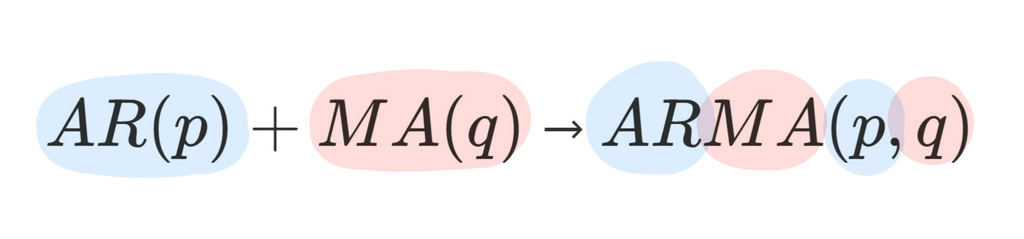 <br>
AR과 MA를 한 식에 합친 모형

> **ARMA 모형의 특징**
- 같은 장부를 AR만으로 설명하려면 여러 시차를 넣어야 함. ARMA는 더 적은 계수로 설명할 수 있음.
- ARMA 모형도 마찬가지로 **AR 부분이 정상성** 조건을, **MA 부분이 가역성** 조건을 각각 만족해야 함.

> **ARMA 모형 특수 케이스**
| 모형 | 의미 |
| --- | --- |
| ARMA(p,0) | MA 부분이 없음. AR(p)와 같음 |
| ARMA(0,q) | AR 부분이 없음. MA(q)와 같음 |
| ARMA(0,0) | 둘 다 없음. 상수에 충격만 더한 백색잡음 |

#### 차수 결정 방법 : 자기 상관 함수 (ACF, PACF)
1. ACF
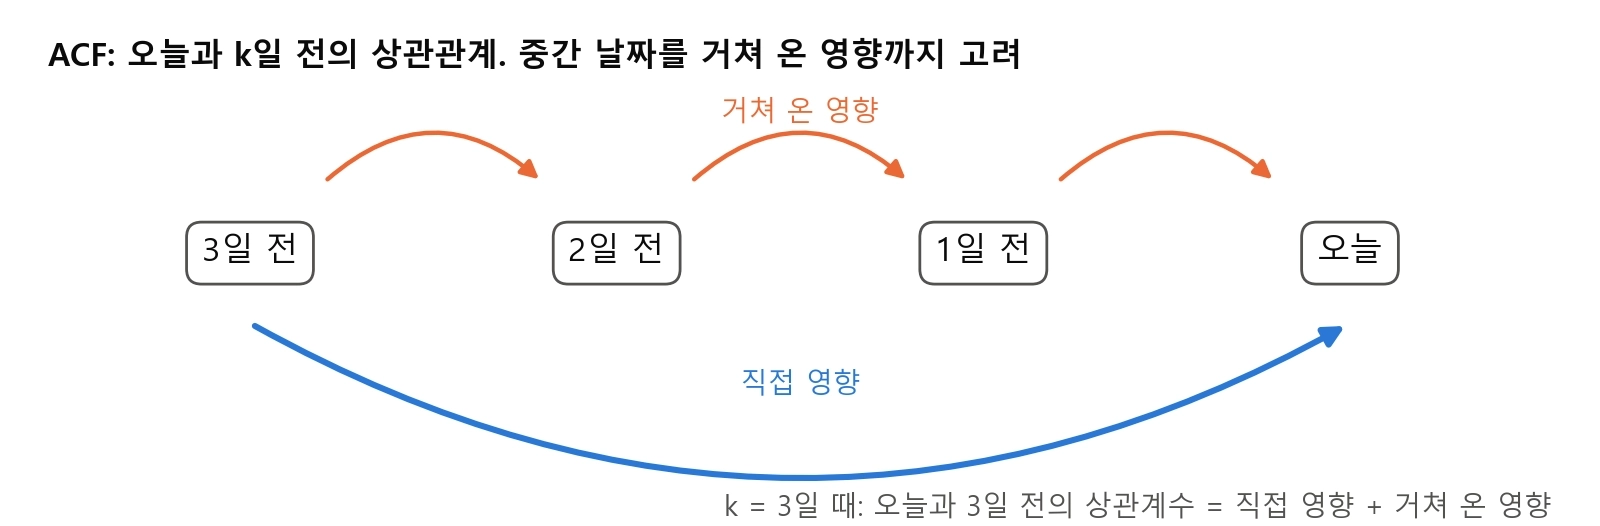 <br>
> **특징**
- −1에서 1 사이의 값을 가집니다. 시차 0에서는 항상 1
- 중간 날짜를 거쳐 온 영향까지 합쳐서 잼.
- 그래프의 점선 안쪽이면 0으로 봄. 점선은 보통 $\pm 1.96/\sqrt{n}$

2. PACF
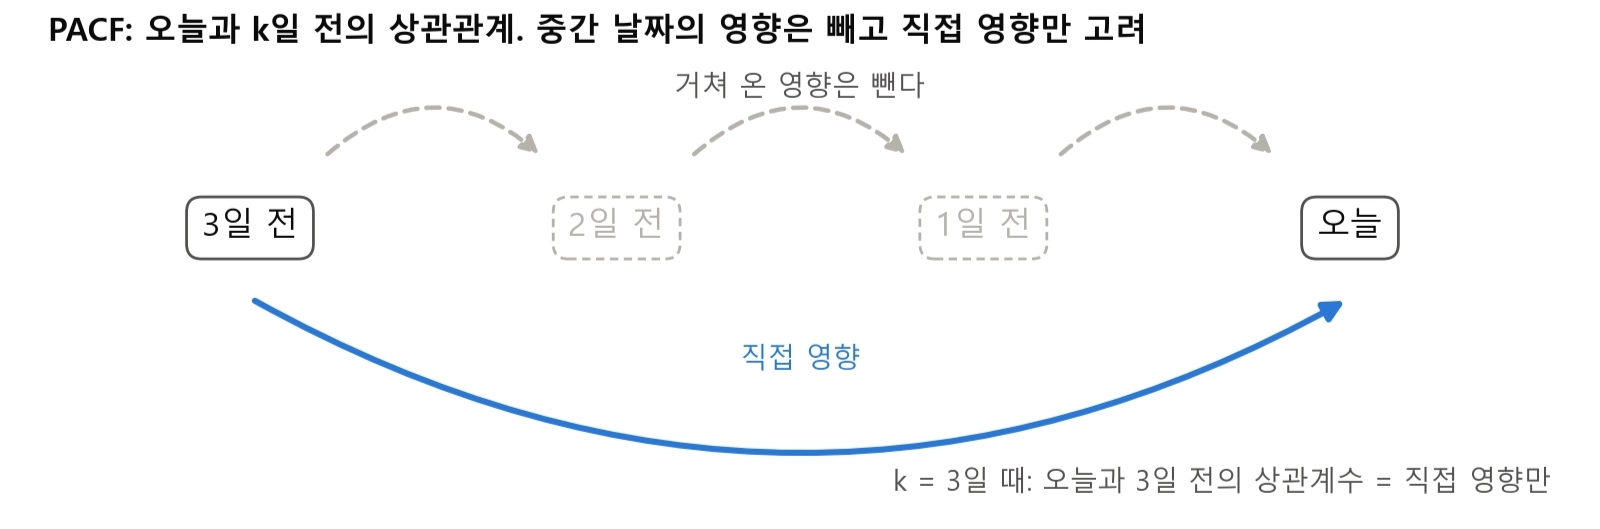 <br>
> **특징**
- 시차 1에서는 중간 날짜가 없으므로 ACF와 값이 같음.

| **ACF 그래프** 모습 | **PACF 그래프** 모습 | **선택 모델 및 차수** |
| --- | --- | --- |
| 천천히 감소 or 진동 감소 | p+1 시점부터 0에 근접 | **AR(p) (= ARMA(p, 0)),** p = 절단 시점 |
| q+1 시점부터 0에 근접 | 천천히 감소 or 진동 감소 | **MA(q) (= ARMA(0, q)) ,** q= 절단 시점 |
| q+1 시점부터 0에 근접 | p+1 시점부터 0에 근접 | **ARMA(p, q)** |

#### 불안정 시계열 분석
정상성이 없는 시계열
<aside>

##### 불안정한 데이터의 시계열 분석 프로세스
1. 비정상 시계열 데이터 (추세 or 계절성 존재)
2. **정상성 확보** (차분 or 계절성 차분)
3. 정상 시계열
4. ARMA를 사용해 **안정적 시계열 분석**

-----------------------------------

##### ARIMA
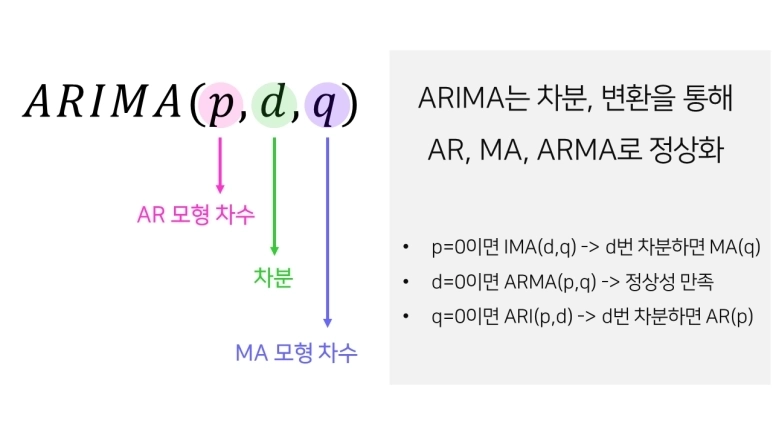 <br>

ARMA에 차분을 더한 모형. ARMA가 판매량을 다루던 자리에 증감을 넣은 것.
- $ARIMA(p,d,q)$
    - $p$: AR 차수
    - $d$: 차분 횟수
    - $q$: MA 차수

|  | 1일 | 2일 | 3일 | 4일 | 5일 | 6일 예측 |
| --- | --- | --- | --- | --- | --- | --- |
| 판매량 | 100 | 103 | 104 | 108 | 110 | 112.5 |
| 어제 대비 증감 |  | +3 | +1 | +4 | +2 | +2.5 |

1. 차분해서 증감을 만들기
2. 증감을 예측
3. 예측한 증감을 어제 판매량에 더함

##### SARIMA
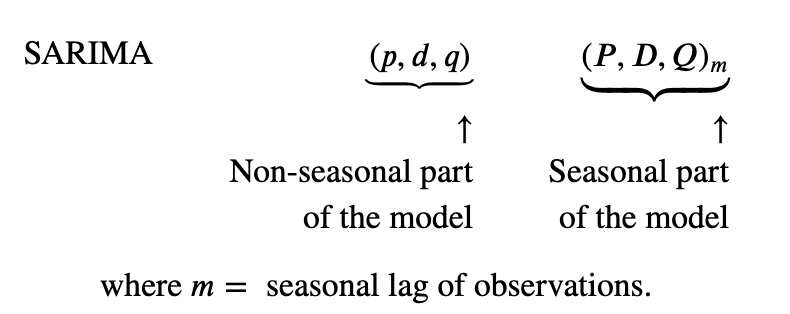 <br>
ARIMA에서 증감은 **지난달 대비**. SARIMA는 여기에 **작년 같은 달 대비** 증감을 더한 것
|  | 10월 | 11월 | 12월 |
| --- | --- | --- | --- |
| 작년 판매량 | 200 | 500 | 900 |
| 올해 판매량 | 250 | 550 | 950 (예측) |
| 작년 같은 달 대비 증감 | +50 | +50 | +50 (예측) |

1. 계절 차분
2. 증감 예측
3. 판매량으로 되돌리기

- 하이퍼파라미터

| 기호 | 이름 | 의미 |
| --- | --- | --- |
| p | 비계절 AR 차수 | 바로 전 시점들의 값을 몇 개 쓰는가 |
| d | 비계절 차분 횟수 | 직전 시점 대비 차분을 몇 번 하는가 |
| q | 비계절 MA 차수 | 바로 전 시점들의 충격을 몇 개 쓰는가 |
| P | 계절 AR 차수 | 한 주기 전, 두 주기 전 값을 몇 개 쓰는가 |
| D | 계절 차분 횟수 | 한 주기 전 대비 차분을 몇 번 하는가 |
| Q | 계절 MA 차수 | 한 주기 전, 두 주기 전 충격을 몇 개 쓰는가 |
| m | 계절 주기 | 한 바퀴가 몇 시점인가. 월별 12, 분기별 4, 요일 효과 7 |

## 다변량 시계열 분석
### VAR
AR을 변수 여러 개로 넓힌 것

단변량 AR(1)은 식이 하나이고, 자기 자신의 어제 값만 들어감.

$$
X_t = a_1 X_{t-1} + \varepsilon_t
$$
-------------------------------------------------------------
다변량 VAR(1)은 변수마다 식이 하나씩 있고, 각 식에 모든 변수의 어제 값이 들어감. 가게로 말하면 X가 판매량, Y가 광고비

$$
X_t = a_{11} X_{t-1} + a_{12} Y_{t-1} + \varepsilon_{x,t}
$$

$$
Y_t = a_{21} X_{t-1} + a_{22} Y_{t-1} + \varepsilon_{y,t}
$$
-------------------------------------------------------------
- **AR 모형의 예시**: 판매량만 봄.
    - 오늘 판매량 = 어제 판매량의 80% + 오늘 충격
    - 광고의 효과는 따로 다루지 못하고 충격 속에 섞여 들어감.
- **VAR 모형의 예시**: 판매량과 광고비를 함께 봄. 광고를 하면 판매량이 늘고, 판매량이 떨어지면 사장님이 광고를 늘림.
    - 오늘 판매량 = 어제 판매량의 60% + 어제 광고비의 30% + 판매 쪽 충격
    - 오늘 광고비 = 어제 광고비의 50% − 어제 판매량의 20% + 광고 쪽 충격

**VAR 모형이 적합한 경우**

- 변수들이 서로 영향을 주고받는 경우 (판매량과 광고비처럼 양방향)
- 예측뿐 아니라 "한 변수가 변하면 다른 변수가 며칠에 걸쳐 어떻게 반응하는가"를 알고 싶을 때
- 모든 변수가 정상이거나, 차분하면 정상이 되는 경우
- 변수의 수가 적고 데이터가 충분한 경우

**VAR 모형이 부적합한 경우**

- 영향이 한 방향뿐인 경우 (기온은 판매량에 영향을 주지만 판매량이 기온을 바꾸지는 않음. 이때는 단변량 모형에 기온을 설명변수로 넣으면 된다.)
- 변수는 많은데 데이터가 적은 경우. (변수가 2개이면 계수가 4개, 3개이면 9개로 빠르게 늘어나기 때문)
- 비율이 고정되지 않은 관계가 강한 경우

#### VAR 모델을 이용한 분석 방법
- 충격 반응 함수 <br>
    한 변수에 충격을 한 번 주었을 때 다른 변수가 시간에 따라 어떻게 반응하는지를 보는 도구
- 예측 오차 분산 분해 <br>
    예측이 빗나가는 것은 예측한 뒤에 들어올 충격을 지금은 모르기 때문입니다. 분산 분해는 빗나간 정도를 "어느 쪽 충격 탓인가"로 나누어 비율로 보여 줌.
